In [2]:
!pip install librosa soundfile numpy scipy matplotlib pandas --quiet

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
import librosa
import numpy as np
import scipy.fft as fft
import matplotlib.pyplot as plt
import pandas as pd
import os

DATASET_PATH = "/content/drive/MyDrive/Señales/UrbanSound8K"
META_PATH    = "/content/drive/MyDrive/Señales/UrbanSound8K/UrbanSound8K.csv"

TARGET_SR = 22050
FRAME_LEN = 512
HOP_LEN   = 128
Ts        = 1 / TARGET_SR

print("PARAMETROS DE MUESTREO")
print(f"Fs  = {TARGET_SR} Hz")
print(f"Ts  = {Ts*1000:.4f} ms")
print(f"Fmax representable = {TARGET_SR//2} Hz")
print(f"Cumple Nyquist: Fs >= 2 x 20000 Hz")

meta = pd.read_csv(META_PATH)
print(f"\nDataset cargada: {len(meta)} audios")
print(f"Clases: {sorted(meta['class'].unique())}")

PARAMETROS DE MUESTREO
Fs  = 22050 Hz
Ts  = 0.0454 ms
Fmax representable = 11025 Hz
Cumple Nyquist: Fs >= 2 x 20000 Hz

Dataset cargada: 8732 audios
Clases: ['air_conditioner', 'car_horn', 'children_playing', 'dog_bark', 'drilling', 'engine_idling', 'gun_shot', 'jackhammer', 'siren', 'street_music']


In [10]:
def cargar_audio(filename, fold):
    ruta = os.path.join(DATASET_PATH, f"fold{fold}", filename)
    y, sr = librosa.load(ruta, sr=TARGET_SR, mono=True)
    y = y / (np.max(np.abs(y)) + 1e-9)
    return y, sr

def caracterizar(y, sr, clase):
    rms = librosa.feature.rms(y=y, frame_length=FRAME_LEN, hop_length=HOP_LEN)[0]
    zcr = librosa.feature.zero_crossing_rate(y, frame_length=FRAME_LEN, hop_length=HOP_LEN)[0]
    return {
        "clase"      : clase,
        "duracion_s" : round(len(y) / sr, 3),
        "n_muestras" : len(y),
        "fs_Hz"      : sr,
        "min"        : round(float(np.min(y)), 4),
        "max"        : round(float(np.max(y)), 4),
        "amplitud"   : round(float(np.max(y) - np.min(y)), 4),
        "rms_media"  : round(float(np.mean(rms)), 4),
        "rms_std"    : round(float(np.std(rms)), 4),
        "zcr_media"  : round(float(np.mean(zcr)), 4),
    }

def calcular_fft(y, sr):
    N        = len(y)
    Y        = fft.rfft(y)
    freqs    = fft.rfftfreq(N, d=1/sr)
    magnitud = np.abs(Y) / N
    return freqs, magnitud

In [11]:
CLASES  = ['siren', 'engine_idling', 'gun_shot', 'children_playing']
colores = ['steelblue', 'darkorange', 'green', 'purple']
audios  = {}
features_tabla = []

for clase in CLASES:
    fila = meta[meta['class'] == clase].iloc[0]
    y, sr = cargar_audio(fila['slice_file_name'], fila['fold'])
    audios[clase] = (y, sr)
    f = caracterizar(y, sr, clase)
    features_tabla.append(f)
    print(f"{clase:<20} {len(y)} muestras | {len(y)/sr:.2f}s | RMS={f['rms_media']} | ZCR={f['zcr_media']}")

df_feat = pd.DataFrame(features_tabla).set_index('clase')

siren                88200 muestras | 4.00s | RMS=0.2038 | ZCR=0.1009
engine_idling        88200 muestras | 4.00s | RMS=0.3703 | ZCR=0.0248
gun_shot             57551 muestras | 2.61s | RMS=0.0548 | ZCR=0.059
children_playing     88200 muestras | 4.00s | RMS=0.1461 | ZCR=0.1394


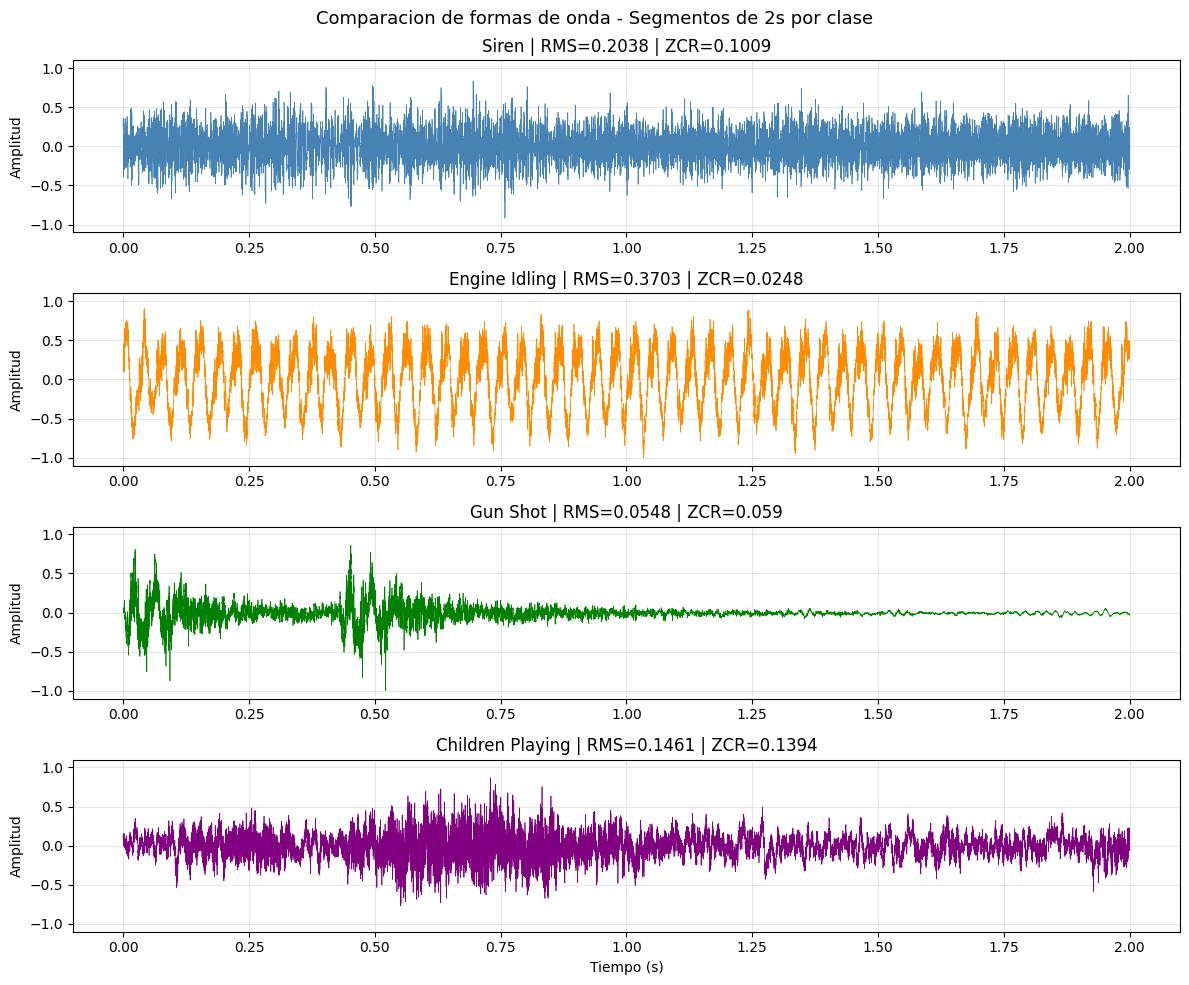

In [12]:
SEG_MUESTRAS = int(2.0 * TARGET_SR)

fig, axs = plt.subplots(4, 1, figsize=(12, 10))
fig.suptitle("Comparacion de formas de onda - Segmentos de 2s por clase", fontsize=13)

for i, clase in enumerate(CLASES):
    y, sr = audios[clase]
    seg = y[:SEG_MUESTRAS]
    t   = np.linspace(0, 2.0, len(seg))
    axs[i].plot(t, seg, linewidth=0.5, color=colores[i])
    axs[i].set_title(f"{clase.replace('_',' ').title()} | RMS={df_feat.loc[clase,'rms_media']} | ZCR={df_feat.loc[clase,'zcr_media']}")
    axs[i].set_ylabel("Amplitud")
    axs[i].set_ylim(-1.1, 1.1)
    axs[i].grid(True, alpha=0.3)

axs[-1].set_xlabel("Tiempo (s)")
plt.tight_layout()
os.makedirs("/content/drive/MyDrive/Señales/resultados", exist_ok=True)
plt.savefig("/content/drive/MyDrive/Señales/resultados/comparacion_formas_onda.png", dpi=150)
plt.show()

# siren: oscilaciones ritmicas, sube y baja de tono
# engine_idling: señal continua y densa, energia sostenida
# gun_shot: pico de energia muy corto al inicio, luego silencio
# children_playing: señal irregular, mezcla de voces

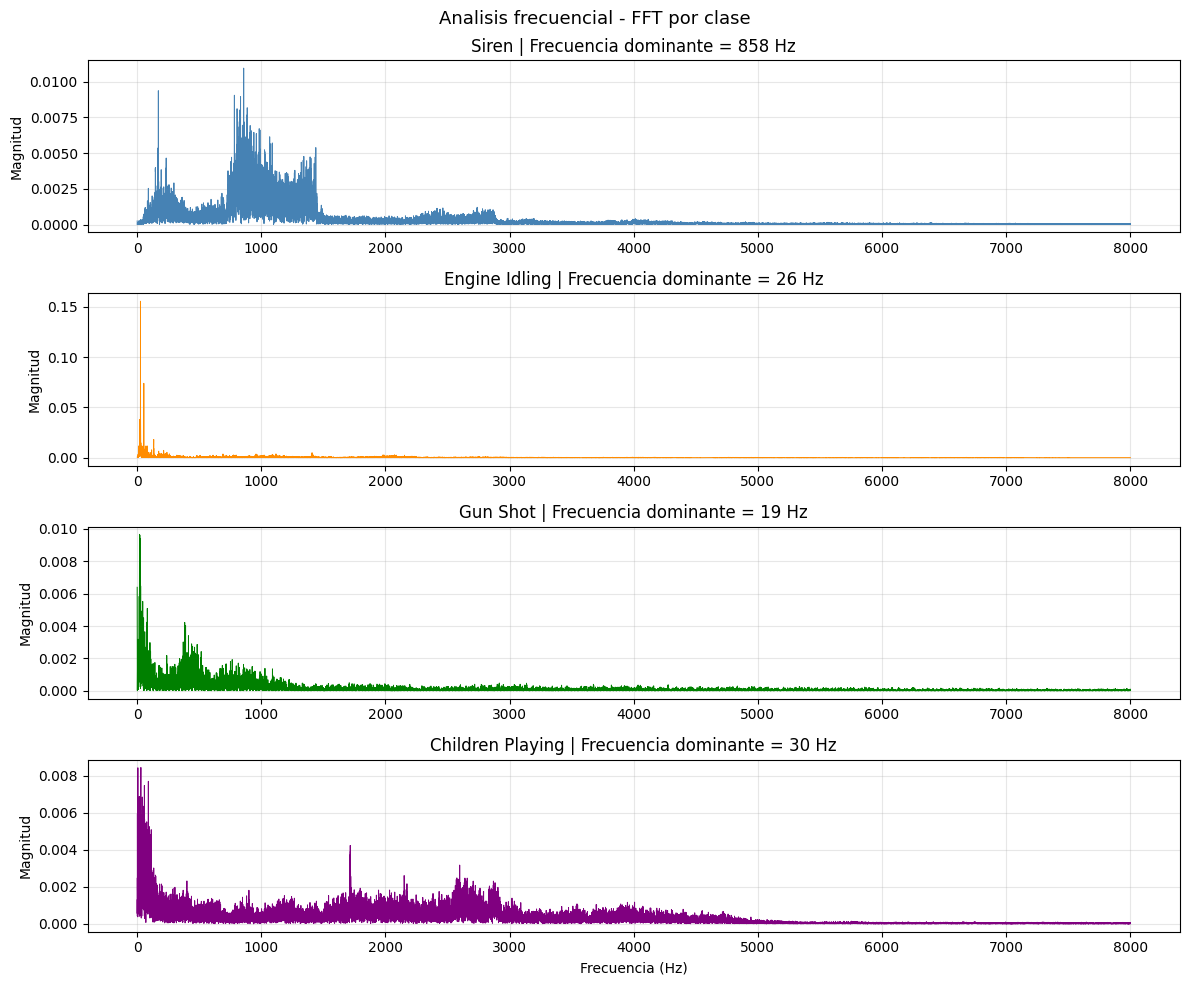

In [13]:
fig, axs = plt.subplots(4, 1, figsize=(12, 10))
fig.suptitle("Analisis frecuencial - FFT por clase", fontsize=13)

for i, clase in enumerate(CLASES):
    y, sr = audios[clase]
    freqs, mag = calcular_fft(y, sr)
    mascara   = freqs <= 8000
    pico_freq = freqs[np.argmax(mag)]
    axs[i].plot(freqs[mascara], mag[mascara], linewidth=0.7, color=colores[i])
    axs[i].set_title(f"{clase.replace('_',' ').title()} | Frecuencia dominante = {pico_freq:.0f} Hz")
    axs[i].set_ylabel("Magnitud")
    axs[i].grid(True, alpha=0.3)

axs[-1].set_xlabel("Frecuencia (Hz)")
plt.tight_layout()
plt.savefig("/content/drive/MyDrive/Señales/resultados/fft_por_clase.png", dpi=150)
plt.show()

# Eje X: frecuencia en Hz - que frecuencias contiene la señal
# Eje Y: magnitud - cuanta energia hay en cada frecuencia
# siren: picos en 500-2000 Hz, tono oscilante
# engine_idling: energia en bajas frecuencias <500 Hz
# gun_shot: energia distribuida en todo el espectro
# children_playing: energia en rango de voz 300-3000 Hz

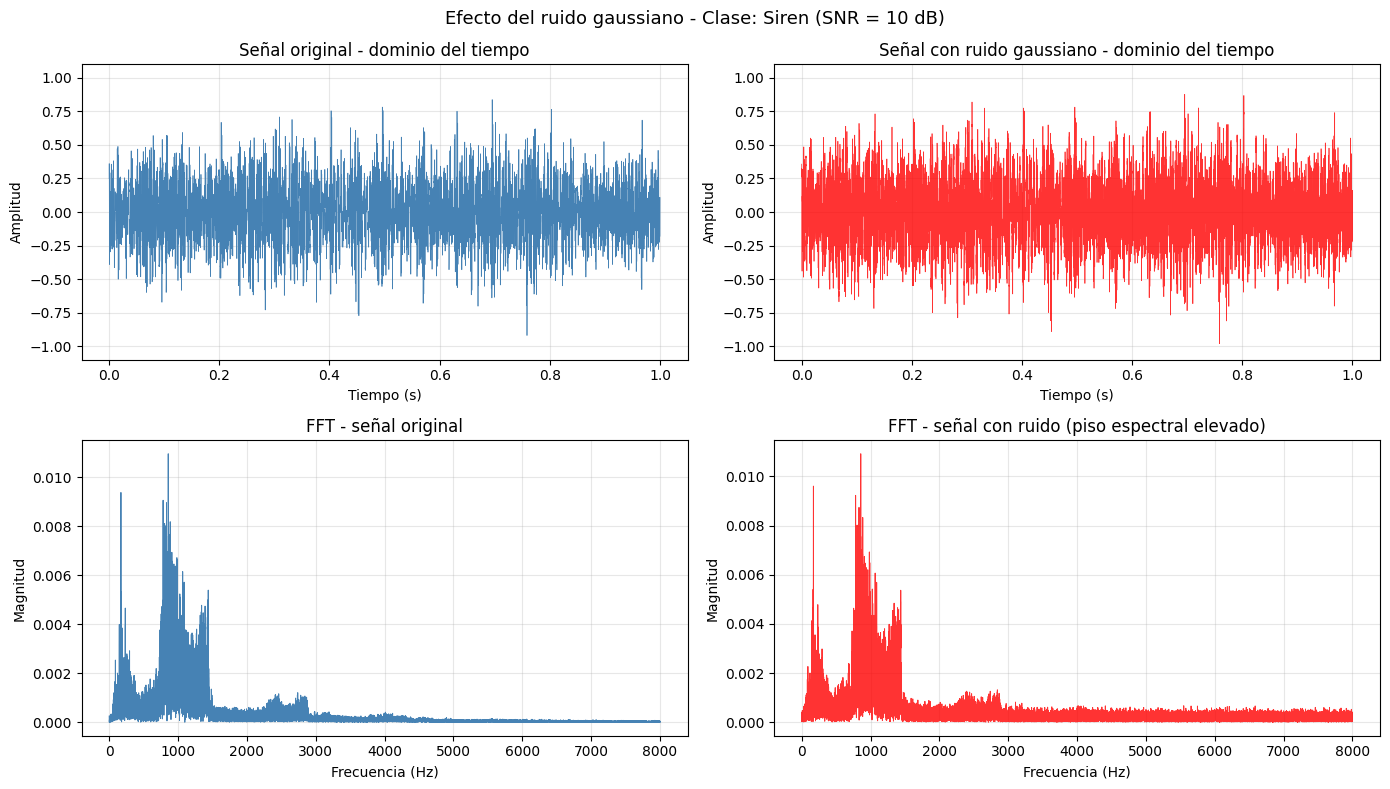

In [14]:
def agregar_ruido(y, snr_db):
    potencia_señal = np.mean(y ** 2)
    potencia_ruido = potencia_señal / (10 ** (snr_db / 10))
    ruido = np.random.normal(0, np.sqrt(potencia_ruido), len(y))
    return y + ruido

y_orig, sr  = audios['siren']
y_ruidoso   = agregar_ruido(y_orig, snr_db=10)
freqs_o, mag_o = calcular_fft(y_orig, sr)
freqs_r, mag_r = calcular_fft(y_ruidoso, sr)
mascara = freqs_o <= 8000
t1s     = np.linspace(0, 1, TARGET_SR)

fig, axs = plt.subplots(2, 2, figsize=(14, 8))
fig.suptitle("Efecto del ruido gaussiano - Clase: Siren (SNR = 10 dB)", fontsize=13)

axs[0,0].plot(t1s, y_orig[:TARGET_SR], linewidth=0.5, color='steelblue')
axs[0,0].set_title("Señal original - dominio del tiempo")
axs[0,0].set_ylabel("Amplitud"); axs[0,0].set_xlabel("Tiempo (s)")
axs[0,0].set_ylim(-1.1, 1.1); axs[0,0].grid(True, alpha=0.3)

axs[0,1].plot(t1s, y_ruidoso[:TARGET_SR], linewidth=0.5, color='red', alpha=0.8)
axs[0,1].set_title("Señal con ruido gaussiano - dominio del tiempo")
axs[0,1].set_ylabel("Amplitud"); axs[0,1].set_xlabel("Tiempo (s)")
axs[0,1].set_ylim(-1.1, 1.1); axs[0,1].grid(True, alpha=0.3)

axs[1,0].plot(freqs_o[mascara], mag_o[mascara], color='steelblue', linewidth=0.7)
axs[1,0].set_title("FFT - señal original")
axs[1,0].set_ylabel("Magnitud"); axs[1,0].set_xlabel("Frecuencia (Hz)")
axs[1,0].grid(True, alpha=0.3)

axs[1,1].plot(freqs_r[mascara], mag_r[mascara], color='red', linewidth=0.7, alpha=0.8)
axs[1,1].set_title("FFT - señal con ruido (piso espectral elevado)")
axs[1,1].set_ylabel("Magnitud"); axs[1,1].set_xlabel("Frecuencia (Hz)")
axs[1,1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("/content/drive/MyDrive/Señales/resultados/comparacion_ruido.png", dpi=150)
plt.show()

# El ruido gaussiano eleva el piso del espectro
# Los picos de la sirena siguen visibles pero con menos contraste
# Esto justifica el uso de filtros en la entrega final

In [15]:
columnas = ['duracion_s','n_muestras','fs_Hz','min','max','amplitud','rms_media','rms_std','zcr_media']
print("TABLA DE CARACTERIZACION - PROYECTO 8: CLASIFICACION DE RUIDO AMBIENTAL")
print(df_feat[columnas].to_string())

df_feat.to_csv("/content/drive/MyDrive/Señales/resultados/tabla_caracterizacion.csv")
print("Tabla guardada en Drive")

TABLA DE CARACTERIZACION - PROYECTO 8: CLASIFICACION DE RUIDO AMBIENTAL
                  duracion_s  n_muestras  fs_Hz     min     max  amplitud  rms_media  rms_std  zcr_media
clase                                                                                                   
siren                   4.00       88200  22050 -0.9193  1.0000    1.9193     0.2038   0.0447     0.1009
engine_idling           4.00       88200  22050 -1.0000  0.9041    1.9041     0.3703   0.0564     0.0248
gun_shot                2.61       57551  22050 -1.0000  0.8588    1.8588     0.0548   0.0694     0.0590
children_playing        4.00       88200  22050 -0.9495  1.0000    1.9495     0.1461   0.0447     0.1394
Tabla guardada en Drive
